In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("/Users/ranganath/Desktop/Human_Activity_Recognition/data/DS DATA.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.shape

(31991, 8)

In [4]:
df.head()

,accX,accY,accZ,gyroX,gyroY,gyroZ,timestamp,Activity
0,-0.496517,3.785628,8.954828,-0.142849,-0.126159,-0.022539,34:22.9,1
1,-0.462388,3.869603,9.281898,0.084349,0.096695,0.092130,34:23.0,1
2,-0.296084,3.820505,8.930728,0.061763,0.051543,0.071287,34:23.1,1
3,-0.469723,3.890110,8.744067,0.007641,0.028679,0.109433,34:23.2,1
4,-0.472418,4.109105,8.941207,-0.123640,0.099057,0.051943,34:23.3,1


In [5]:
df.columns

Index(['accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ', 'timestamp',
       'Activity'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31991 entries, 0 to 31990
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   accX       31991 non-null  float64
 1   accY       31991 non-null  float64
 2   accZ       31991 non-null  float64
 3   gyroX      31991 non-null  float64
 4   gyroY      31991 non-null  float64
 5   gyroZ      31991 non-null  float64
 6   timestamp  31991 non-null  str    
 7   Activity   31991 non-null  int64  
dtypes: float64(6), int64(1), str(1)
memory usage: 2.2 MB


DATA CLEANING


In [7]:
df.isnull().sum()

accX         0
accY         0
accZ         0
gyroX        0
gyroY        0
gyroZ        0
timestamp    0
Activity     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(144)

In [9]:
df = df.drop_duplicates()

In [10]:
df.shape

(31847, 8)

EDA

In [11]:
df["Activity"].value_counts()

Activity
1    31276
0      571
Name: count, dtype: int64

In [12]:
df["Activity"].value_counts(normalize=True) * 100

Activity
1    98.207052
0     1.792948
Name: proportion, dtype: float64

In [13]:
df["Activity"].unique()

array([1, 0])

In [14]:
df.describe()

,accX,accY,accZ,gyroX,gyroY,gyroZ,Activity
count,31847.000000,31847.000000,31847.000000,31847.000000,31847.000000,31847.000000,31847.000000
mean,0.026158,2.152577,9.538051,-0.004459,-0.014737,-0.007106,0.982071
std,0.741464,1.086719,2.056548,0.307732,0.249245,0.266290,0.132697
min,-3.673361,-4.386029,4.296066,-1.470421,-1.430659,-1.894102,0.000000
25%,-0.469499,1.409469,7.794067,-0.149783,-0.162515,-0.154353,1.000000
50%,-0.021705,2.117497,9.407487,0.022291,-0.011062,0.005099,1.000000
75%,0.479453,2.927014,11.158695,0.177924,0.124854,0.152061,1.000000
max,4.678671,6.377039,17.591568,1.332722,1.480135,1.482268,1.000000


In [15]:
df.groupby("Activity")[[
    "accX", "accY", "accZ",
    "gyroX", "gyroY", "gyroZ"
]].mean()

,accX,accY,accZ,gyroX,gyroY,gyroZ
Activity,,,,,,
0,-0.673363,1.240090,9.758294,-0.007847,-0.011786,0.011653
1,0.038929,2.169236,9.534030,-0.004397,-0.014791,-0.007449


Sensor distributions

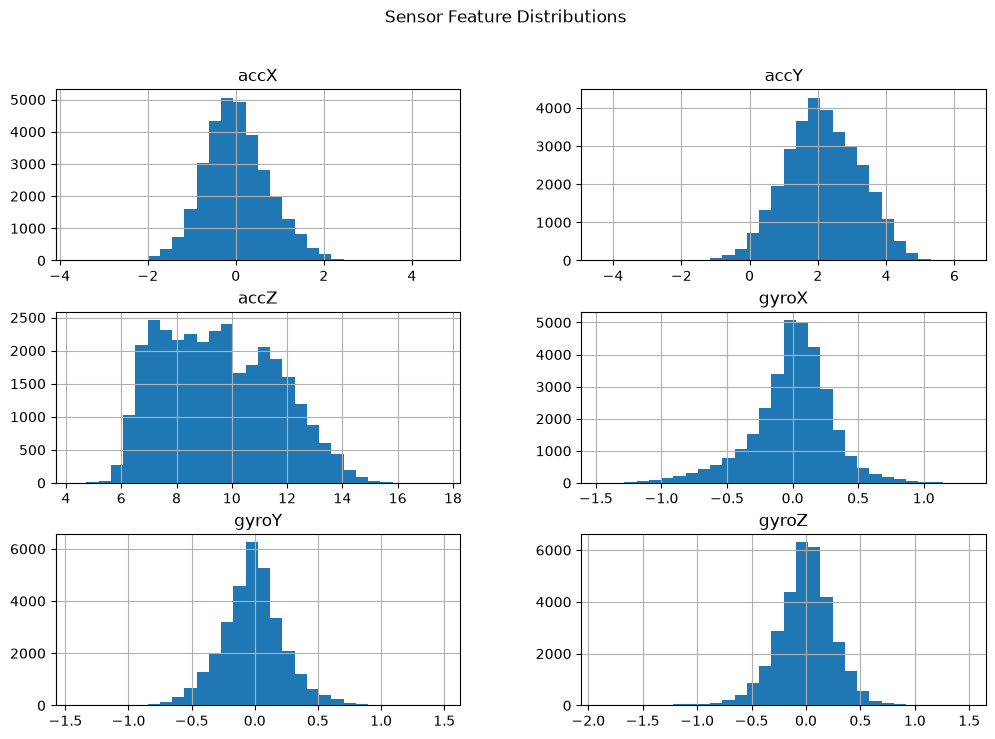

In [16]:
df[["accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ"]].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Sensor Feature Distributions")
plt.show()

Activity distribution graph

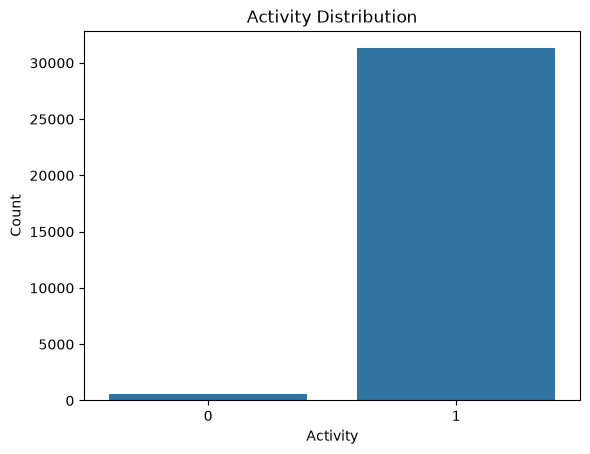

In [17]:
sns.countplot(x="Activity", data=df)

plt.title("Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Count")
plt.show()

Outlier detection

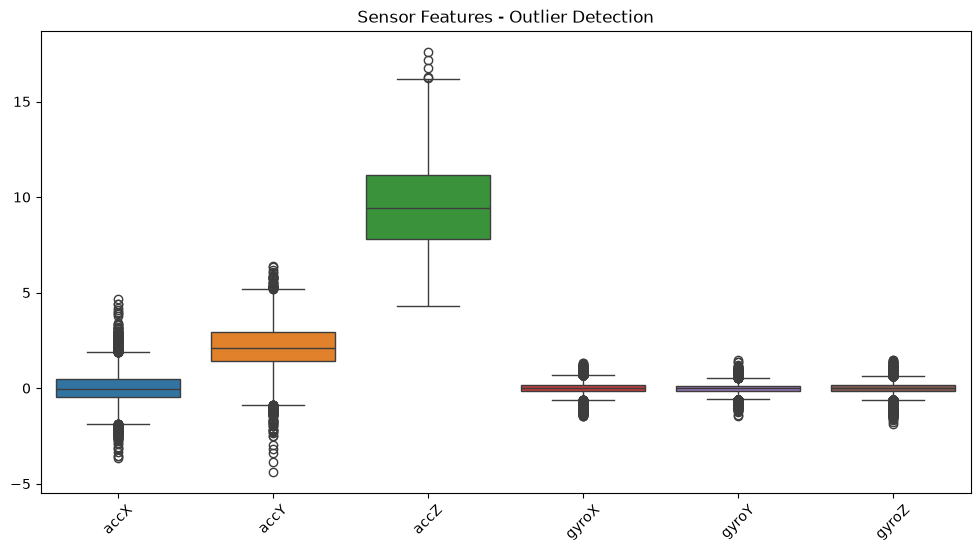

In [18]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[["accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ"]]
)

plt.title("Sensor Features - Outlier Detection")
plt.xticks(rotation=45)
plt.show()

Correlation heatmap

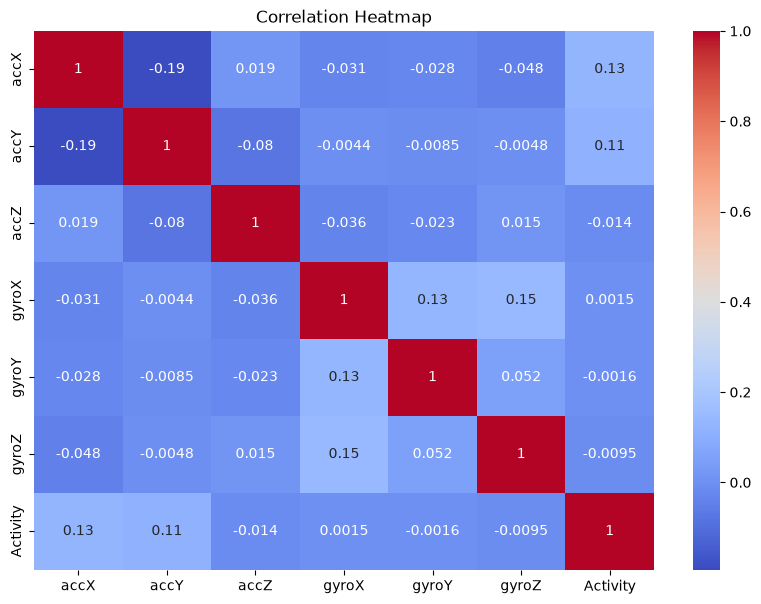

In [19]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

Features vs Activity

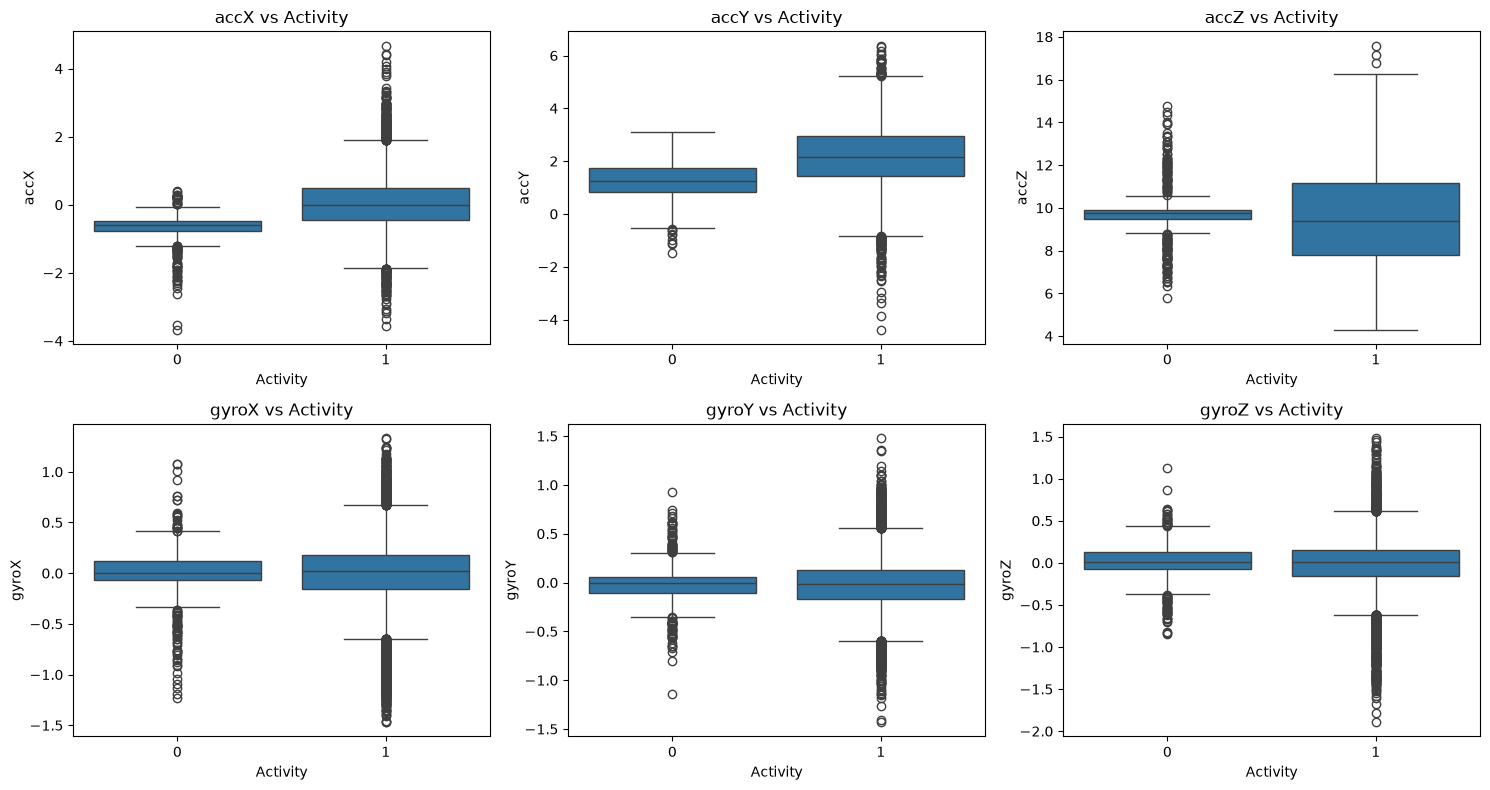

In [20]:
features = ["accX", "accY", "accZ", "gyroX", "gyroY", "gyroZ"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(
        x="Activity",
        y=feature,
        data=df,
        ax=ax
    )
    ax.set_title(f"{feature} vs Activity")

plt.tight_layout()
plt.show()

In [21]:
df["timestamp"].head()

0    34:22.9
1    34:23.0
2    34:23.1
3    34:23.2
4    34:23.3
Name: timestamp, dtype: str

In [22]:
df = df.drop(columns=["timestamp"])

TARGET SEPARATION

In [23]:
X = df.drop(columns=["Activity"])
y = df["Activity"]

In [24]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (31847, 6)
y shape: (31847,)


TRAIN / TEST SPLIT

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (25477, 6)
X_test : (6370, 6)
y_train: (25477,)
y_test : (6370,)


In [27]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
Activity
1    25020
0      457
Name: count, dtype: int64

Testing distribution:
Activity
1    6256
0     114
Name: count, dtype: int64


handle class imbalance

In [28]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(27.87417943107221), np.int64(1): np.float64(0.5091326938449241)}


Feature Scaling

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (25477, 6)
X_test_scaled shape: (6370, 6)


Logistic Regression

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


log_model = LogisticRegression(
    class_weight=class_weights,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)


y_pred_log = log_model.predict(X_test_scaled)


y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]


print("Logistic Regression Evaluation")
print("=" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob_log))

Logistic Regression Evaluation
Accuracy: 0.7872841444270016

Classification Report:
              precision    recall  f1-score   support

           0       0.07      0.92      0.13       114
           1       1.00      0.78      0.88      6256

    accuracy                           0.79      6370
   macro avg       0.54      0.85      0.51      6370
weighted avg       0.98      0.79      0.87      6370

Confusion Matrix:
[[ 105    9]
 [1346 4910]]

ROC-AUC: 0.8932954188540404


Decision Tree

In [32]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight=class_weights,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [33]:
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [34]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Decision Tree Evaluation")
print("=" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob_dt))

Decision Tree Evaluation
Accuracy: 0.9747252747252747

Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.23      0.24       114
           1       0.99      0.99      0.99      6256

    accuracy                           0.97      6370
   macro avg       0.62      0.61      0.62      6370
weighted avg       0.97      0.97      0.97      6370

Confusion Matrix:
[[  26   88]
 [  73 6183]]

ROC-AUC: 0.6082006887423161


Random Forest

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight=class_weights,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [36]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [37]:
print("Random Forest Evaluation")
print("=" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest Evaluation
Accuracy: 0.9802197802197802

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.36      0.39       114
           1       0.99      0.99      0.99      6256

    accuracy                           0.98      6370
   macro avg       0.71      0.68      0.69      6370
weighted avg       0.98      0.98      0.98      6370

Confusion Matrix:
[[  41   73]
 [  53 6203]]

ROC-AUC: 0.9324781543052003


Hyperparameter Tuning

In [38]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight=class_weights,
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Grid Search completed!")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Grid Search completed!


Best Parameters

In [39]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.9506901311249137


In [40]:
best_rf_model = grid_search.best_estimator_

print("Best Random Forest model created!")

Best Random Forest model created!


In [41]:
y_pred_best_rf = best_rf_model.predict(X_test)
y_prob_best_rf = best_rf_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Evaluation")
print("=" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_best_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_rf))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob_best_rf))

Tuned Random Forest Evaluation
Accuracy: 0.9511773940345369

Classification Report:
              precision    recall  f1-score   support

           0       0.23      0.73      0.35       114
           1       0.99      0.96      0.97      6256

    accuracy                           0.95      6370
   macro avg       0.61      0.84      0.66      6370
weighted avg       0.98      0.95      0.96      6370

Confusion Matrix:
[[  83   31]
 [ 280 5976]]

ROC-AUC: 0.948099648898461


In [42]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.9506901311249137


Feature Importance

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

  Feature  Importance
0    accX    0.380303
1    accY    0.288265
2    accZ    0.148536
3   gyroX    0.066296
5   gyroZ    0.060765
4   gyroY    0.055835


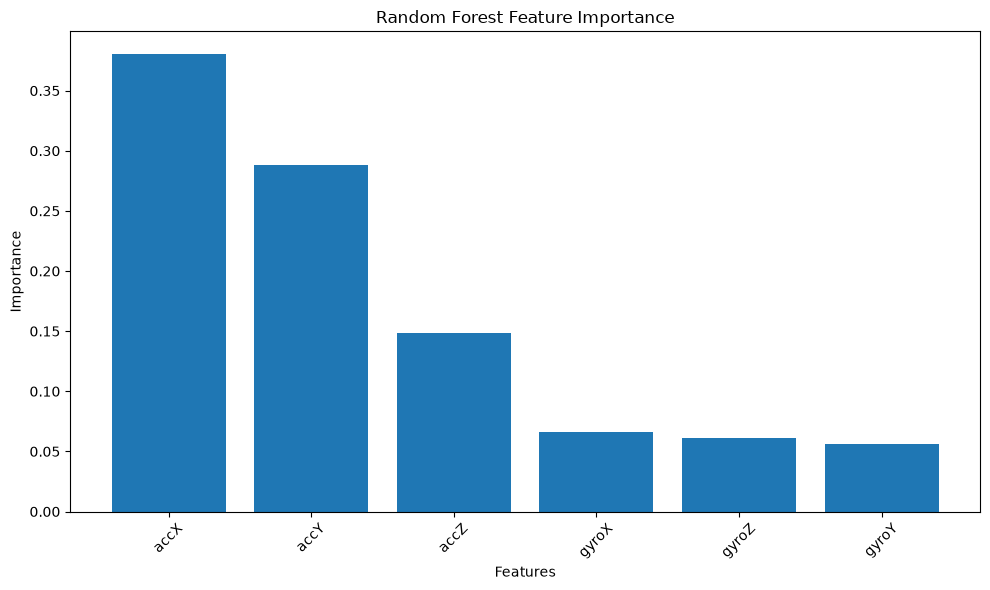

In [44]:
plt.figure(figsize=(10, 6))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

save model

In [45]:
import os

os.makedirs("../models", exist_ok=True)

print("Models folder ready!")

Models folder ready!


In [46]:
import joblib

joblib.dump(best_rf_model, "../models/human_activity_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [47]:
import os

model_path = "../models/human_activity_model.pkl"

if os.path.exists(model_path):
    print("Model file exists!")
    print("Path:", model_path)
else:
    print("Model file not found!")

Model file exists!
Path: ../models/human_activity_model.pkl


In [48]:
loaded_model = joblib.load("../models/human_activity_model.pkl")

print("Saved model loaded successfully!")
print(loaded_model)

Saved model loaded successfully!
RandomForestClassifier(class_weight={np.int64(0): np.float64(27.87417943107221),
                                     np.int64(1): np.float64(0.5091326938449241)},
                       max_depth=10, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)


Find the missing number
Input: [1,2,3,5]
Output:4

In [ ]:
a=[1,2,3,5]
n = len(a) + 1
print("Length of t